<a href="https://colab.research.google.com/github/muneeb0065/Deep-Learning/blob/main/Customer_Churn_Prediction_using_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
import pandas as pd
import numpy as np

In [62]:
data = pd.read_csv('Churn_Modelling.csv')

In [63]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [64]:
# First 3 columns are not much important so we will remove them
data = data.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [65]:
# Now we will one hat encoding of Geography and Gender Column
data = pd.get_dummies(data,columns=['Geography','Gender'],drop_first=True)


In [66]:
data.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [67]:
# Now we will split the data in Input and Output

# X = data.iloc[:, 0:11] # This throw error because our output column is in the center so we will split as:
X = data.drop(columns=['Exited'])
y = data['Exited'].values

In [68]:
# Now we will split the data into training and testing data

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=0)

In [69]:
X_train.shape

(8000, 11)

In [70]:
# Now we will do feature scaling

from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()

X_train_transformed = scalar.fit_transform(X_train)
X_test_transformed = scalar.transform(X_test)

In [71]:
# NOW we will create our Neural Network using Keras TensorFlow
# The requires Libraries are

import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [20]:
# Now we can create sequential and non sequential models and here we are creating a sequential model

model = Sequential()

# Now will will create our hidden layers

model.add(Dense(3, activation='sigmoid', input_dim = 11)) # This is our 1st hidden layer and we have to tell it will get its input from input layers which are 11.
model.add(Dense(2,activation='sigmoid')) # This is 2nd hidden layer
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [72]:
# Now the to improve the accuracy we are experimenting by changing the loss function and no of layers

model = Sequential()

model.add(Dense(6, activation='relu', input_dim = 11))
model.add(Dense(4,activation='relu'))
model.add(Dense(1,activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [73]:
model.summary()  # This tells the summary our our model like the total number of trainable parameters in our model

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 6)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105 (420.00 B)

 Trainable params: 105 (420.00 B)

 Non-trainable params: 0 (0.00 B)

In [83]:
# Now we have to compile our model in which we tell which loss function we are using and optimizer for gradient descent

model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=['accuracy']) # By adding the metrics='accuracy' it will show the accuracy at each epoch

In [84]:
# Now we will fit our model and this is the stage where our neural network is trained
# We can tell the no of epochs and other important params
history = model.fit(X_train_transformed, y_train, epochs=50, validation_split=0.2) # here validation split means while training phase our model split the training data(8000) into 80% and 20% test so it trains and test on that 20% data during each epcoch and we should make sure the the accuracy on validation set also increases with the accuracy on the actual training data.

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8364 - loss: 0.3831 - val_accuracy: 0.8275 - val_loss: 0.4022
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8348 - loss: 0.3818 - val_accuracy: 0.8375 - val_loss: 0.3960
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8378 - loss: 0.3796 - val_accuracy: 0.8356 - val_loss: 0.3957
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8384 - loss: 0.3784 - val_accuracy: 0.8381 - val_loss: 0.3957
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8386 - loss: 0.3779 - val_accuracy: 0.8375 - val_loss: 0.3872
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8389 - loss: 0.3769 - val_accuracy: 0.8338 - val_loss: 0.3892
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8389 - loss: 0.3762 - val_accuracy: 0.8400 - val_loss: 0.3932
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8422 - loss: 0.3749 - val_accuracy: 0.

In [85]:
# Now our model is trained and we can see our weights of each layer

model.layers[0].get_weights()

[array([[ 0.07510273,  0.00699225, -0.07619013, -0.04898018, -0.00603114,
          0.15467764],
        [ 0.15385245,  0.2067247 , -0.5575552 , -0.30799615,  0.01077828,
         -1.0515317 ],
        [ 0.00656567, -0.04108725, -0.02103174, -0.13637286, -0.02869691,
         -0.11748451],
        [ 0.13784935,  0.304515  , -0.2951254 ,  0.34367165, -0.33547097,
          0.35342675],
        [-0.3252883 ,  1.2431931 ,  0.13218097, -0.8160178 , -0.6347546 ,
         -0.16263476],
        [-0.01872111, -0.00771271,  0.04276483, -0.1597594 ,  0.08982138,
         -0.07075135],
        [-0.5030228 , -0.2595824 ,  0.55799216,  0.18873698, -0.31754795,
         -0.5062629 ],
        [ 0.0671839 ,  0.04202859,  0.04490156, -0.20817634,  0.22072692,
          0.1136262 ],
        [ 0.42294526, -0.12442657, -0.13441673,  0.35870138, -0.62895167,
         -0.2546045 ],
        [ 0.09648441,  0.02549489, -0.09789736,  0.23986216, -0.15260248,
         -0.02482732],
        [-0.07160479, -0.11740

In [86]:
# Now we can make predictions
y_pred = model.predict(X_test_transformed)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [87]:
y_pred
# Here you can see we use sigmoid function so the output is not is 0 and 1 so we need to select the best threshold through ROCAUC curve and for now we are using the threshold as 0.5.

array([[0.35331517],
       [0.4001965 ],
       [0.22571872],
       ...,
       [0.19053137],
       [0.23400281],
       [0.23421623]], shape=(2000, 1), dtype=float32)

In [88]:
y_pred = np.where(y_pred>0.5,1,0)

# Now it is in 0 and 1
print(y_pred)

[[0]
 [0]
 [0]
 ...
 [0]
 [0]
 [0]]


In [89]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.858

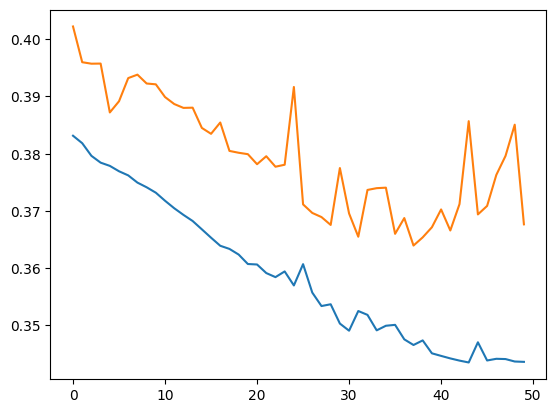

In [92]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

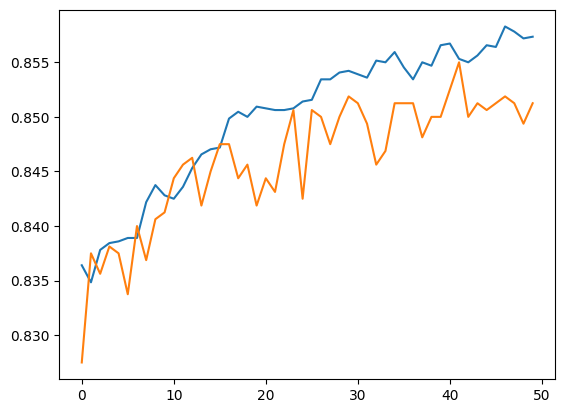

In [93]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])